<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C23_Notebook-27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

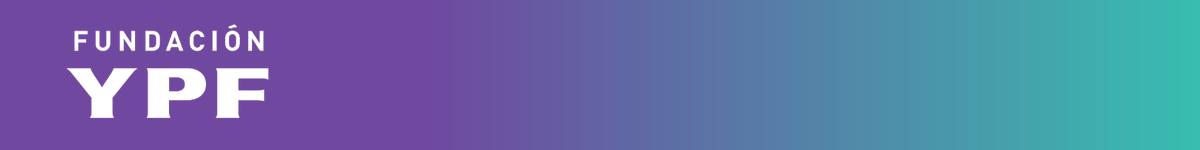

# Fundación YPF - Data Science

## Notebook 27: Singular Value Decomposition (SVD) y PCA

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: clustering sobre los clientes del centro comercial
* **Parte 2:** Singular Value Decomposition (SVD)
* **Parte 3:** Matriz truncada: cómo elegir r
* **Parte 4:** PCA y su relación con SVD
* **Parte 5:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En las clases anteriores agrupamos a los clientes de un centro comercial con **K-Means** (Notebook 23), **DBSCAN** (Notebook 25) y medimos la calidad de esos clusters con el método del codo y el coeficiente de Silhouette (Notebook 26). En la Notebook 23 también dimos un primer vistazo a **PCA** para graficar en dos dimensiones. Hoy abrimos esa caja: vemos cómo funciona por dentro la **Singular Value Decomposition (SVD)**, el método de álgebra lineal que PCA usa internamente, y cómo se elige cuántas dimensiones conservar.

**Datasets:**

* `clientes_mall.csv`: los mismos clientes del centro comercial (Notebooks 23, 25 y 26). Esta vez trabajamos con las 3 variables numéricas juntas (edad, ingreso y puntaje) para tener una matriz con más de 2 features y que la reducción de dimensionalidad tenga sentido.
* `cancer_mamario.csv`: datos clínicos de pacientes con cáncer de mama. Lo usamos en el ejercicio de las salas.

Antes de ejecutar, subí los archivos `clientes_mall.csv` y `cancer_mamario.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [ ]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: clustering sobre los clientes del centro comercial

Volvemos a los clientes del centro comercial, igual que en las Notebooks 23, 25 y 26, pero esta vez usamos **las 3 variables numéricas juntas**: edad, ingreso anual y puntaje de gasto. Con 2 variables podíamos graficar y ver los grupos a simple vista. Con 3 ya no podemos, y es justo el problema que resuelve la reducción de dimensionalidad: representar los datos con menos variables sin perder la estructura.

In [ ]:
if not os.path.exists("clientes_mall.csv"):
    from google.colab import files
    files.upload()

clientes = pd.read_csv("clientes_mall.csv").drop(columns=["Unnamed: 0", "CustomerID"])
clientes.columns = ["Genero", "Edad", "Ingreso", "Puntaje"]

# Igual que en las Notebooks 23, 25 y 26: nos quedamos con los clientes con datos numéricos completos
datos = clientes.dropna(subset=["Edad", "Ingreso", "Puntaje"]).reset_index(drop=True)
print("Clientes:", len(datos))

variables = ["Edad", "Ingreso", "Puntaje"]
X = StandardScaler().fit_transform(datos[variables])
print("Forma de la matriz X (instancias x features):", X.shape)

Clientes: 161
Forma de la matriz X (instancias x features): (161, 3)


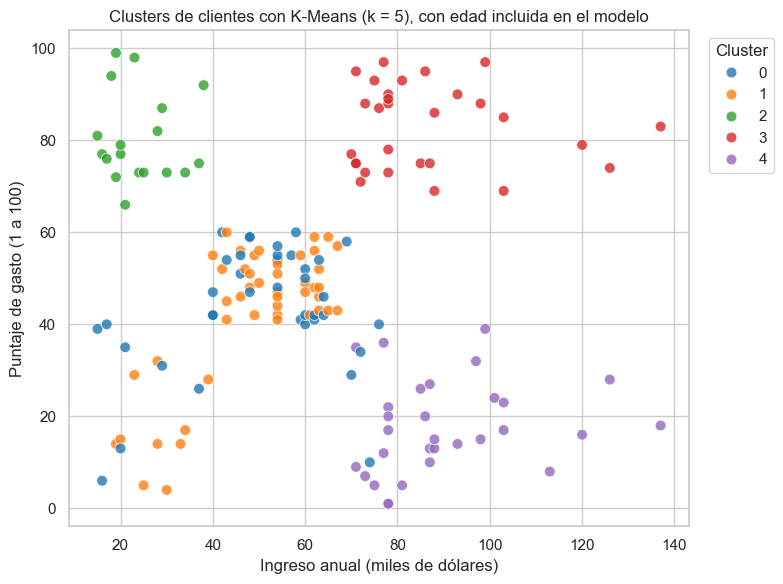

In [ ]:
datos["cluster"] = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit_predict(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=datos, x="Ingreso", y="Puntaje", hue="cluster", palette="tab10", s=60, alpha=0.8)
plt.title("Clusters de clientes con K-Means (k = 5), con edad incluida en el modelo")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto (1 a 100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Los clusters de siempre, ahora armados con 3 variables en vez de 2. El gráfico de arriba solo muestra 2 de las 3 (ingreso y puntaje): la edad quedó afuera porque ya no entra en un gráfico plano. Para ver las 3 variables juntas, sin elegir cuál dejar afuera, necesitamos reducir la dimensionalidad. Veamos cómo lo hace SVD.

## Parte 2: Singular Value Decomposition (SVD)

La **Singular Value Decomposition** es un método de álgebra lineal que descompone cualquier matriz M (m instancias por n features) como el producto de 3 matrices:

**M = U . Sigma . V transpuesta**

* **U** (m x m): matriz de vectores singulares por izquierda.
* **Sigma** (m x n): matriz diagonal con los **valores singulares**, ordenados de mayor a menor.
* **V transpuesta** (n x n): matriz de vectores singulares por derecha.

Lo calculamos con `numpy.linalg.svd` sobre la matriz `X` ya escalada (161 clientes, 3 features).

In [ ]:
U, S, Vt = np.linalg.svd(X, full_matrices=False)

print("Forma de X (M):", X.shape)
print("Forma de U:", U.shape)
print("Forma de S (valores singulares):", S.shape)
print("Forma de Vt:", Vt.shape)
print()
print("Valores singulares:", S.round(2))

Forma de X (M): (161, 3)
Forma de U: (161, 3)
Forma de S (valores singulares): (3,)
Forma de Vt: (3, 3)

Valores singulares: [14.6  12.63 10.5 ]


Con `full_matrices=False` numpy devuelve las versiones "económicas" de U y Sigma (sin las columnas de ceros que no aportan información), pero la igualdad M = U . Sigma . V transpuesta se sigue cumpliendo. Lo verificamos reconstruyendo la matriz original.

In [ ]:
M_reconstruida = U @ np.diag(S) @ Vt
error_reconstruccion = np.abs(X - M_reconstruida).max()
print("Maxima diferencia entre X y U . Sigma . V transpuesta:", error_reconstruccion)

Maxima diferencia entre X y U . Sigma . V transpuesta: 1.9984014443252818e-15


## Parte 3: Matriz truncada: cómo elegir r

Si en vez de usar las n columnas de U y V nos quedamos solo con las primeras **r** (las de los r valores singulares más grandes), construimos una matriz truncada B que ya no es exactamente igual a M, pero la aproxima. Reducir r es reducir la dimensionalidad.

Para elegir r, la clase mostró dos criterios:

1. **Distancia entre M y la matriz truncada:** SVD garantiza que, para un r dado, B es la mejor aproximación posible de M (la que minimiza esa distancia).
2. **Peso relativo de los valores singulares elegidos:** qué proporción de la suma de los valores singulares (al cuadrado) representan los primeros r frente al total. Es la "varianza explicada".

Calculamos los dos criterios para cada valor posible de r.

In [ ]:
n_features = X.shape[1]
filas = []
for r in range(1, n_features + 1):
    B = U[:, :r] @ np.diag(S[:r]) @ Vt[:r, :]
    distancia = np.linalg.norm(X - B)
    varianza_explicada = (S[:r] ** 2).sum() / (S ** 2).sum()
    filas.append({
        "r": r,
        "distancia_frobenius(M, B)": round(distancia, 3),
        "varianza_explicada": round(varianza_explicada, 3),
    })

tabla_r = pd.DataFrame(filas)
tabla_r

,r,"distancia_frobenius(M, B)",varianza_explicada
0,1,16.423,0.442
1,2,10.503,0.772
2,3,0.000,1.000


Con r = 3 (todas las features) la distancia es 0: no truncamos nada. A medida que baja r, la distancia crece y la varianza explicada baja: con r = 1 la distancia es 16.4 y se retiene el 44% de la varianza; con r = 2 la distancia baja a 10.5 y se retiene el 77%. Es una mejora grande frente a r = 1, y ya podemos graficar en un plano, así que r = 2 es el valor que usamos de acá en adelante.

## Parte 4: PCA y su relación con SVD

La clase mostró que **PCA = centrar los datos + SVD truncado**. Como `X` ya está estandarizada (media 0, desvío 1), ya está centrada. Comparamos la proyección en 2 componentes que arma `sklearn.decomposition.PCA` con la que armamos a mano usando U y Sigma truncados en la Parte 3.

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca.fit_transform(X)

print("Varianza explicada por cada componente (PCA):", pca.explained_variance_ratio_.round(3))
print("Varianza explicada total (PCA):", pca.explained_variance_ratio_.sum().round(3))

Varianza explicada por cada componente (PCA): [0.442 0.33 ]
Varianza explicada total (PCA): 0.772


La varianza explicada total de PCA (77%) coincide con la que calculamos a mano para r = 2 en la Parte 3: son el mismo cálculo. Confirmamos que la proyección también coincide, comparando con la que arma SVD truncado (`U[:, :r] * S[:r]`, equivalente a multiplicar la matriz centrada por `V transpuesta` truncada). Los signos pueden salir invertidos entre los dos métodos (es una ambigüedad propia de SVD: U y V pueden multiplicarse por -1 a la vez sin cambiar el resultado), así que comparamos en valor absoluto.

In [ ]:
r = 2
Z_svd = U[:, :r] * S[:r]

diferencia = np.abs(np.abs(Z_pca) - np.abs(Z_svd)).max()
print("Maxima diferencia (en valor absoluto) entre la proyeccion de PCA y la de SVD truncado:", round(diferencia, 6))

Maxima diferencia (en valor absoluto) entre la proyeccion de PCA y la de SVD truncado: 0.0


Graficamos a los clientes en el plano de los 2 componentes, coloreados por el cluster que encontramos en la Parte 1. Es la "Representación Gráfica" que vimos en la clase, ahora con nuestros propios datos.

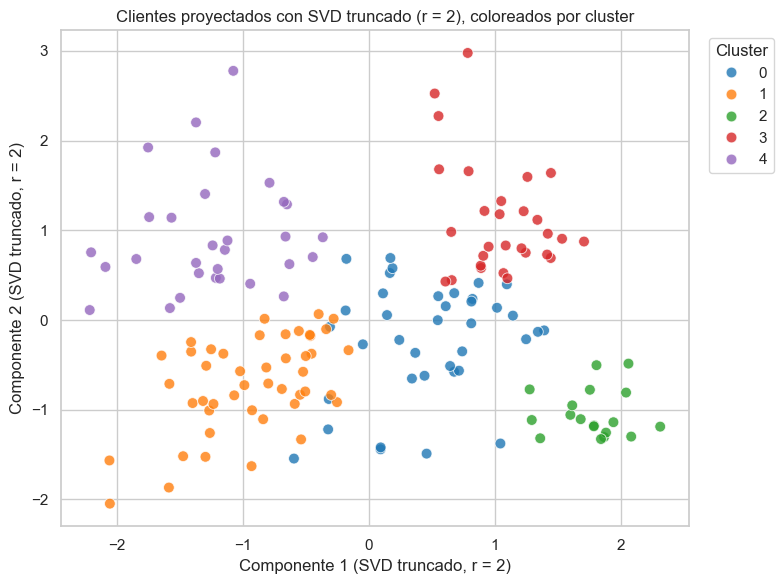

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_pca[:, 0], y=Z_pca[:, 1], hue=datos["cluster"], palette="tab10", s=60, alpha=0.8)
plt.xlabel("Componente 1 (SVD truncado, r = 2)")
plt.ylabel("Componente 2 (SVD truncado, r = 2)")
plt.title("Clientes proyectados con SVD truncado (r = 2), coloreados por cluster")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Los clusters que K-Means armó con las 3 variables originales se ven razonablemente separados también en el plano de 2 componentes: es una señal de que esas 2 dimensiones conservan la estructura que le importa al clustering.

**PCA vs. SVD, en resumen (como en la tabla de la clase):**

| Parámetro | PCA | SVD |
| --- | --- | --- |
| Número de componentes | Número de componentes | Rango r |
| Qué encuentra | Componentes principales | Vectores singulares por derecha |
| Qué pesa cada componente | Autovalores | Valores singulares |
| Qué optimiza | Maximiza varianza | Minimiza distancia |

Son dos formas de ver el mismo resultado: PCA parte de la covarianza de los datos centrados, SVD descompone la matriz directamente. Por eso, centrando los datos, PCA no es más que SVD truncado.

## Parte 5: Ejercicio para las salas de Zoom

**Dataset:** `cancer_mamario.csv`. Datos clínicos de 286 pacientes con cáncer de mama: edad (en rangos), estado de menopausia, tamaño del tumor (en rangos), ganglios invadidos (en rangos), si hay cápsula ganglionar afectada, grado de malignidad (1 a 3), lado de la mama, cuadrante y si recibió radioterapia. La columna `class` indica si hubo recurrencia de la enfermedad.

**Contexto:** a diferencia de `clientes_mall`, acá casi todas las variables son categóricas (texto) y algunas son rangos (por ejemplo `age` viene como `'40-49'`). SVD y PCA solo funcionan sobre matrices numéricas, así que primero hay que convertir cada columna a un número.

**Objetivo:** reducir el dataset a 2 dimensiones con SVD o PCA y ver si las pacientes con y sin recurrencia se distinguen en ese plano.

**Tiempo:** 45 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Codificación de variables categóricas.** Convertí a número las columnas de rangos (`age`, `tumor-size`, `inv-nodes`) respetando su orden, y codificá las columnas binarias y nominales (`menopause`, `node-caps`, `breast`, `breast-quad`, `irradiat`). `deg-malig` ya es numérica. Decidí qué hacer con los valores `'?'` (faltantes).
2. **Escalado.** Escalá las variables numéricas resultantes con `StandardScaler`.
3. **SVD o PCA con 2 componentes.** Aplicá lo que vimos en la Parte 2, 3 o 4 (a mano con `numpy.linalg.svd` o con `PCA` de scikit-learn) para quedarte con 2 componentes.
4. **Gráfico.** Graficá a las pacientes en el plano de los 2 componentes, coloreadas por `class`.
5. **Varianza explicada y conclusión.** Calculá cuánta varianza retienen los 2 componentes elegidos. ¿Se distinguen a simple vista las pacientes con y sin recurrencia en ese plano? ¿Qué le dice eso a un modelo de clasificación que usara esas mismas 2 variables?

**Preguntas para la puesta en común:**

* ¿Cómo decidiste codificar `age`, `tumor-size` e `inv-nodes`? ¿Por qué no conviene tratarlas como categorías sin orden?
* ¿Cuánta varianza retuvieron los 2 componentes? ¿Te parece suficiente para confiar en el gráfico?
* Si tuvieras que elegir r mirando los dos criterios de la Parte 3, ¿te hubiese alcanzado con 2 componentes, o hubieras usado más?

In [ ]:
# Cargamos el dataset del ejercicio
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

pacientes = pd.read_csv("cancer_mamario.csv")

print("Forma del dataset:", pacientes.shape)
print()
print("Tipos de dato:")
print(pacientes.dtypes)
print()
print("Valores '?' por columna:")
print((pacientes == "?").sum())
pacientes.head()

Forma del dataset: (286, 10)

Tipos de dato:
class          object
age            object
menopause      object
tumor-size     object
inv-nodes      object
node-caps      object
deg-malig       int64
breast         object
breast-quad    object
irradiat       object
dtype: object

Valores '?' por columna:
class          0
age            0
menopause      0
tumor-size     0
inv-nodes      0
node-caps      8
deg-malig      0
breast         0
breast-quad    1
irradiat       0
dtype: int64


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [ ]:
# 1. Codificación de variables categóricas
# COMPLETAR

In [ ]:
# 2. Escalado
# COMPLETAR

In [ ]:
# 3. SVD o PCA con 2 componentes
# COMPLETAR

In [ ]:
# 4. Grafico de las pacientes proyectadas, coloreadas por class
# COMPLETAR

In [ ]:
# 5. Varianza explicada y conclusion
# COMPLETAR